# 04. Multi-Reservoir Hybrid Cascade (`Feitsui -> Zhitan`)

- **Goal:** Test whether joint-dispatch LLM (`feitsui`) + Hanasaki (`zhitan`) improves downstream storm control.
- **Case & Window (Repo-Only — Not in Paper):** Taiwan Xindian River cascade (`2025` post-cutoff validation vs TFRA & MOEA/WRA rule curve).
- **Pass Criterion:** `verify_run = PASS` on both cascades; Lohmann UH convolution matches `network_flows.csv`.

*Runs 100% offline inside a temporary directory (`0` API cost).*

In [1]:
import json, tempfile
from pathlib import Path
import sys
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

for p in (Path.cwd(), *Path.cwd().parents):
    if (p / "tutorials" / "_helpers.py").is_file():
        sys.path.insert(0, str(p))
        break
from tutorials import _helpers as h
from llm_reservoir_agent.workflow import load_settings

REPO_ROOT = h.find_repo_root()
C = h.configure_plots()

## 1. Inspect Cascade Lag & Causal Joint-Dispatch Prompt

Check Lohmann reach weights (`case.json`) and confirm `hybrid_llm.yaml` passes today's downstream `zhitan_local` inflow causally (`valid_time <= clock`).

In [2]:
mr_dir = REPO_ROOT / "examples" / "multi_reservoir"
case = json.loads((mr_dir / "case.json").read_text(encoding="utf-8"))
for conn in case["network"]["connections"]:
    print(f"Reach {conn['source']} -> {conn['target']}: UH={conn['unit_hydrograph']} (sum={sum(conn['unit_hydrograph']):.6f})")

hyb_plan = load_settings(mr_dir / "hybrid_llm.yaml", runtime_root=REPO_ROOT)
p_lines = hyb_plan.report["prompt_previews"]["feitsui_operator"]["messages"][1]["content"].splitlines()
print("\nDay-1 Joint-Dispatch Prompt lines (note item 7 Nanshi lateral inflow):")
for ln in [l for l in p_lines if l.strip()][:8]:
    print(" ", ln)

Reach feitsui -> zhitan_local: UH=[0.801305, 0.198693, 2e-06] (sum=1.000000)
Reach zhitan -> xindian_outlet: UH=[1.0] (sum=1.000000)

Day-1 Joint-Dispatch Prompt lines (note item 7 Nanshi lateral inflow):
  Date: 2025-01-01 (January, day 1 of the year)
  1. Today's inflow: 11.15 m3/s (= 963,592 m3 (= 0.964 million m3) over 1 days)
  2. Water level at beginning of interval: 168.08 m
  3. Previous simulated release decisions (and what was actually released):
     None (first simulated step).
  4. Number of days in this decision interval: 1
  5. Storage at beginning of interval: 316,895,260 m3 (= 316.895 million m3, 94.5% of capacity)
  6. Controlled release limits for this interval: 0.0-500.0 m3/s (= 0-43,200,000 m3 over 1 days)


## 2. Run Rule-Based & Hybrid LLM Cascades + Verify Routing

Execute both cascades offline (`TemporaryDirectory()`), verify routing convolution, and compare against `expected_scores.csv`.

In [3]:
with tempfile.TemporaryDirectory() as td:
    xd = h.replay_xindian_2025(REPO_ROOT, Path(td))

print("Offline verify_run  :", {k: v["status"] for k, v in xd["verifications"].items()})
print(f"UH convolution diff : {xd['max_routing_diff_cms']:.2e} m3/s")
print(xd["scores"].round(3).to_string(index=False))



Offline verify_run  : {'rule_based': 'PASS', 'hybrid_llm': 'PASS'}
UH convolution diff : 2.27e-13 m3/s
 condition        quantity   kge     r  alpha  beta    nse   rmse
rule_based   Feitsui level 0.915 0.918  1.014 0.981  0.358  3.634
rule_based Feitsui release 0.447 0.480  0.835 1.093  0.100 37.626
rule_based Downstream flow 0.760 0.823  1.148 1.066  0.568 57.481
hybrid_llm   Feitsui level 0.601 0.845  0.633 1.012  0.498  3.213
hybrid_llm Feitsui release 0.460 0.562  1.314 1.040 -0.250 44.346
hybrid_llm Downstream flow 0.690 0.857  1.271 1.043  0.562 57.919


## 3. Storm-Window Joint Dispatch & Full-Year 2025 Trajectories

Zoom into the largest 2025 Nanshi lateral storm to see pre-throttling across Lohmann lags, then check full-year limits against MOEA/WRA dekads.

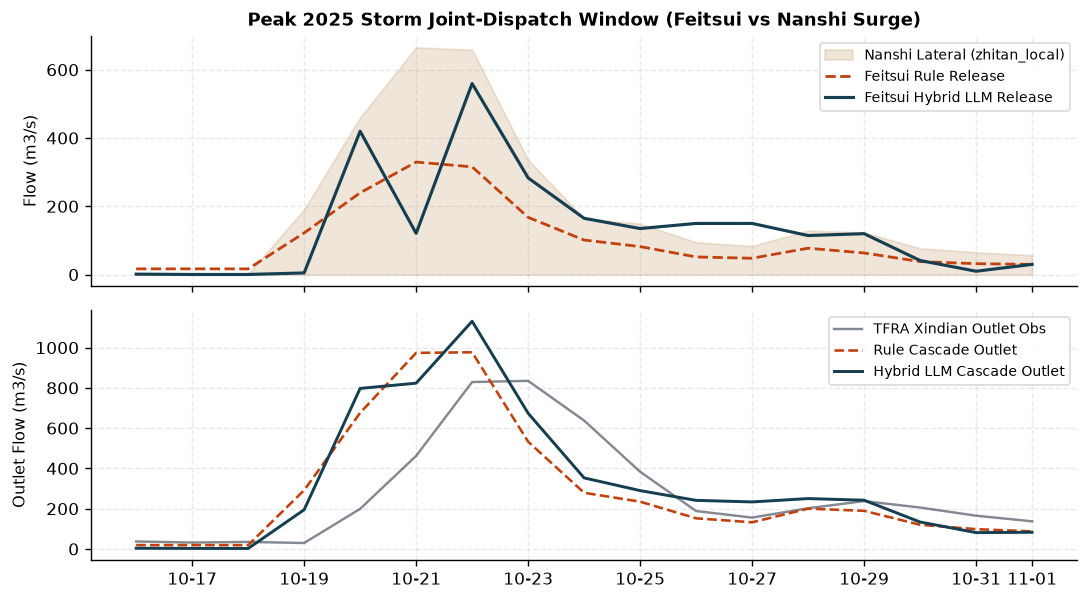

In [4]:
obs = xd["observations"]
inflows = xd["inflows"]
z_loc = inflows[(inflows["node"] == "zhitan_local") & (inflows["date"].isin(obs["date"]))].reset_index(drop=True)
pk_idx = int(np.argmax(z_loc["local_inflow_cms"].to_numpy()))
lo, hi = max(0, pk_idx - 5), min(len(obs), pk_idx + 12)
dates_win = obs["date"].iloc[lo:hi].tolist()
d_dt = pd.to_datetime(dates_win)

def _slice(traj_df, flow_df):
    f_r = traj_df[(traj_df["reservoir_id"] == "feitsui") & (traj_df["date_key"].isin(dates_win))]["total_outflow_cms"].to_numpy()
    o_r = flow_df[(flow_df["node"] == "xindian_outlet") & (flow_df["date_key"].isin(dates_win))]["routed_flow_cms"].to_numpy()
    return f_r, o_r

rf_win, ro_win = _slice(xd["rule_traj"], xd["rule_flows"])
hf_win, ho_win = _slice(xd["hybrid_traj"], xd["hybrid_flows"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.8, 4.9), sharex=True)
ax1.fill_between(d_dt, 0, z_loc["local_inflow_cms"].iloc[lo:hi], color=C["gold"], alpha=0.22, label="Nanshi Lateral (zhitan_local)")
ax1.plot(d_dt, rf_win, color=C["coral"], ls="--", lw=1.6, label="Feitsui Rule Release")
ax1.plot(d_dt, hf_win, color=C["navy"], lw=1.8, label="Feitsui Hybrid LLM Release")
ax1.set_ylabel("Flow (m3/s)"); ax1.set_title("Peak 2025 Storm Joint-Dispatch Window (Feitsui vs Nanshi Surge)")
ax1.legend(loc="upper right", fontsize=8)

ax2.plot(d_dt, obs["downstream_flow_cms"].iloc[lo:hi], color=C["obs"], alpha=0.55, lw=1.4, label="TFRA Xindian Outlet Obs")
ax2.plot(d_dt, ro_win, color=C["coral"], ls="--", lw=1.5, label="Rule Cascade Outlet")
ax2.plot(d_dt, ho_win, color=C["navy"], lw=1.7, label="Hybrid LLM Cascade Outlet")
ax2.set_ylabel("Outlet Flow (m3/s)"); ax2.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax2.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

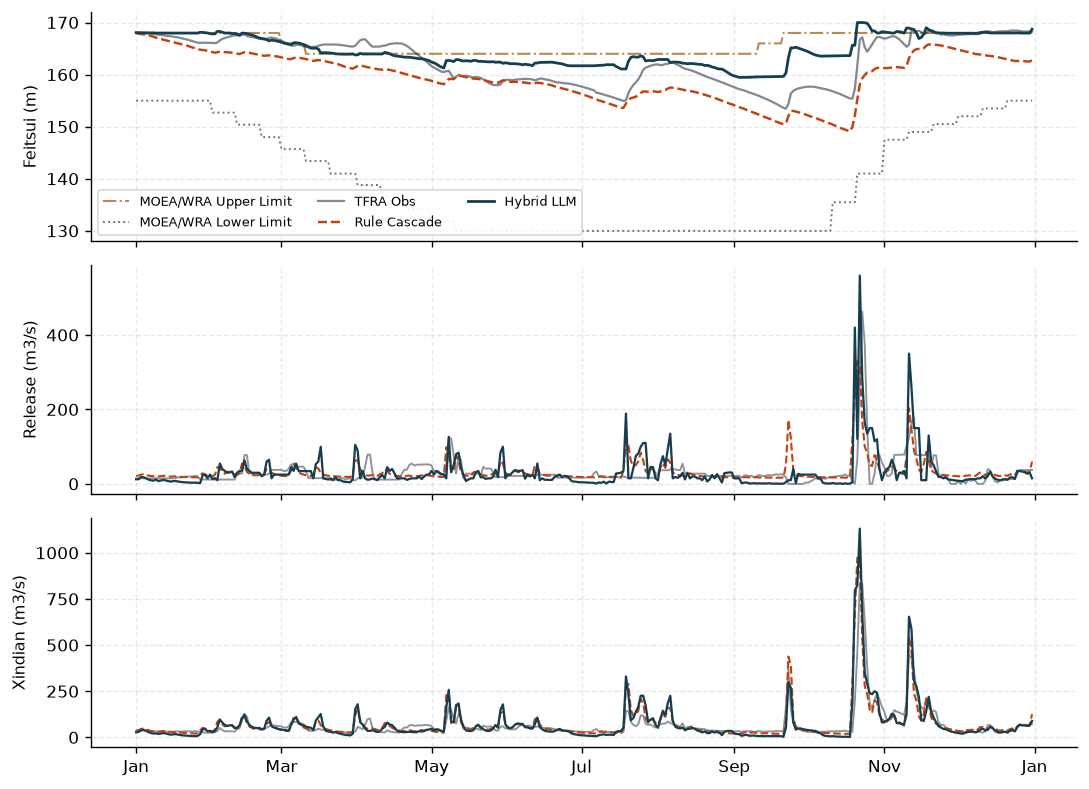

In [5]:
dates_all = obs["date"].tolist()
dt_all, rc = obs["date_dt"], xd["rule_curve_daily"]
_, _, to_elev_m = h.load_feitsui_curve(REPO_ROOT)

def _full(traj_df, flow_df):
    ft = traj_df[(traj_df["reservoir_id"] == "feitsui") & (traj_df["date_key"].isin(dates_all))].copy()
    lvl = [to_elev_m(v) for v in ft["storage_end_m3"]]
    rel = ft["total_outflow_cms"].to_numpy()
    out = flow_df[(flow_df["node"] == "xindian_outlet") & (flow_df["date_key"].isin(dates_all))]["routed_flow_cms"].to_numpy()
    return lvl, rel, out

rl, rr, ro = _full(xd["rule_traj"], xd["rule_flows"])
hl, hr, ho = _full(xd["hybrid_traj"], xd["hybrid_flows"])
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8.8, 6.4), sharex=True)
ax1.plot(dt_all, rc["upper_limit_m"], color=C["gold"], ls="-.", lw=1.2, label="MOEA/WRA Upper Limit")
ax1.plot(dt_all, rc["lower_limit_m"], color=C["muted"], ls=":", lw=1.1, label="MOEA/WRA Lower Limit")
ax1.plot(dt_all, obs["feitsui_elevation_m"], color=C["obs"], alpha=0.55, lw=1.3, label="TFRA Obs")
ax1.plot(dt_all, rl, color=C["coral"], ls="--", lw=1.4, label="Rule Cascade")
ax1.plot(dt_all, hl, color=C["navy"], lw=1.6, label="Hybrid LLM")
ax1.set_ylabel("Feitsui (m)"); ax1.legend(loc="lower left", ncol=3, fontsize=7.5)

ax2.plot(dt_all, obs["feitsui_outflow_cms"], color=C["obs"], alpha=0.5, lw=1.1)
ax2.plot(dt_all, rr, color=C["coral"], ls="--", lw=1.2); ax2.plot(dt_all, hr, color=C["navy"], lw=1.3)
ax2.set_ylabel("Release (m3/s)")

ax3.plot(dt_all, obs["downstream_flow_cms"], color=C["obs"], alpha=0.5, lw=1.1)
ax3.plot(dt_all, ro, color=C["coral"], ls="--", lw=1.2); ax3.plot(dt_all, ho, color=C["navy"], lw=1.3)
ax3.set_ylabel("Xindian (m3/s)"); ax3.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.tight_layout(); plt.show()

- **Rule vs. Hybrid:** Hybrid LLM trims Feitsui level error; dual Hanasaki tracks annual level KGE closely.
- **Lohmann lag:** Outlet flow blends upstream lagged releases with Nanshi inflows under mass conservation.

## 4. Adapt to Your Basin

- **Cascade links (`case.json`):** Add downstream `connections` with reach `unit_hydrograph` (`sum = 1.0`).
- **Causal gauges (`information.yaml`):** Gate cross-dam feeds via `valid_time <= clock`, `issued_at <= clock`, `required: false`.
- **Live Ollama:** `ollama pull gemma4:12b` -> set `max_calls` -> `--allow-network`.

Next: [Module 05](../05_odd_llm_reproducibility_and_audit/05_odd_llm_reproducibility.ipynb)